# Cloud Workload Forecasting — Data Understanding & EDA

This notebook performs the required data-understanding and exploratory analysis
(assignment section A). All logic lives in `src/cwfc`; this notebook only calls
into it and renders the results, per the architecture note in the assignment.


In [1]:

import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cwfc.data import load_cpu_readings, load_vm_metadata
from cwfc.quality import audit_cpu_readings
from cwfc.targets import build_target_series
from cwfc.splits import train_holdout_split

DATA_DIR = REPO_ROOT / "challenge_data"
FIG_DIR = REPO_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 20)
plt.rcParams["figure.dpi"] = 110


## 1. Load raw data

In [2]:

cpu = load_cpu_readings(DATA_DIR)
meta = load_vm_metadata(DATA_DIR)
print("cpu readings:", cpu.shape)
print("vm metadata:", meta.shape)
cpu.head()


cpu readings: (1340000, 5)
vm metadata: (10000, 11)


,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


## 2. Structural quality audit

Cadence, coverage, duplicates, missingness, VM trace completeness — computed by
`cwfc.quality.audit_cpu_readings`, not eyeballed.


In [3]:

report = audit_cpu_readings(cpu, meta)
for field_name in report.__dataclass_fields__:
    if field_name == "notes":
        continue
    print(f"{field_name:30s}: {getattr(report, field_name)}")
print()
print("Notes:")
for n in report.notes:
    print(" -", n)


n_rows                        : 1340000
n_vms                         : 10000
n_timestamps                  : 134
timestamp_min                 : 0
timestamp_max                 : 39900
cadence_seconds               : 300
irregular_cadence             : False
n_duplicate_vm_timestamp      : 0
readings_per_vm_min           : 134
readings_per_vm_max           : 134
vms_with_incomplete_trace     : 0
n_missing_avg_cpu             : 0
n_missing_min_cpu             : 0
n_missing_max_cpu             : 0
n_rows_avg_outside_min_max    : 0
avg_cpu_min                   : 0.007158921626865188
avg_cpu_max                   : 99.48802665399455
metadata_vm_mismatch          : 0
metadata_duplicate_vm         : 0

Notes:
 - Every VM has a reading at every timestamp: active_vm_count(t) is constant by construction (the release only includes VMs with complete traces).


**Why this matters operationally:** a perfectly regular 5-minute grid with zero
duplicates and zero missing readings means no imputation or resampling decisions
are forced on us — any model performance difference we measure reflects the
workload itself, not data-cleaning choices. This is not guaranteed in production
telemetry (agents can drop samples, clocks can skew), so a production pipeline
would still need these same checks as a continuous data-quality gate, not a
one-off audit.

## 3. VM lifetimes and churn

In [4]:

meta["created_dt"] = meta["timestamp_vm_created"]
meta["deleted_dt"] = meta["timestamp_vm_deleted"]
window_end = cpu["timestamp"].max()

print("timestamp_vm_created distribution:")
print(meta["created_dt"].describe())
print()
print("timestamp_vm_deleted distribution:")
print(meta["deleted_dt"].describe())
print()
n_created_before_window = (meta["created_dt"] <= 0).sum()
n_deleted_within_window = (meta["deleted_dt"] <= window_end).sum()
print(f"VMs created at/before window start: {n_created_before_window} / {len(meta)}")
print(f"VMs with deletion timestamp inside the observed window: {n_deleted_within_window} / {len(meta)}")


timestamp_vm_created distribution:
count    10000.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: created_dt, dtype: float64

timestamp_vm_deleted distribution:
count    1.000000e+04
mean     2.289626e+06
std      7.081008e+05
min      4.050000e+04
25%      2.591400e+06
50%      2.591400e+06
75%      2.591400e+06
max      2.591400e+06
Name: deleted_dt, dtype: float64

VMs created at/before window start: 10000 / 10000
VMs with deletion timestamp inside the observed window: 0 / 10000


All 10,000 VMs were already running at the start of the observed window, and the
large majority have a recorded deletion timestamp (~2.59M seconds, i.e. the end of
the full 30-day upstream trace) far beyond our 134-point window. Combined with
"every VM has exactly 134 readings" from the audit above, there is **no VM churn
inside this dataset by construction** — the curators only kept VMs with complete
traces. This is why `active_vm_count(t)` will turn out to be constant below.
A real-time capacity system cannot assume this; it is an artifact of how this
take-home sample was built, and the report calls this out as a limitation.

## 4. Build the required target series

In [5]:

targets = build_target_series(cpu)
print(targets.shape)
targets.head()


(134, 3)


,timestamp,active_vm_count,aggregate_cpu_utilization
0,0,10000,9.396898
1,300,10000,9.353775
2,600,10000,9.454383
3,900,10000,9.224419
4,1200,10000,9.143503


In [6]:

print("active_vm_count unique values:", targets["active_vm_count"].unique())
print("active_vm_count std:", targets["active_vm_count"].std())


active_vm_count unique values: [10000]
active_vm_count std: 0.0


Confirmed: `active_vm_count` is exactly 10,000 at every timestamp, zero variance.
There is no churn signal in this release for the model to learn — forecasting this
target correctly means recognizing and stating this, not fitting a model to noise.
The real forecasting problem is entirely in `aggregate_cpu_utilization`.

## 5. aggregate_cpu_utilization: distribution and temporal pattern

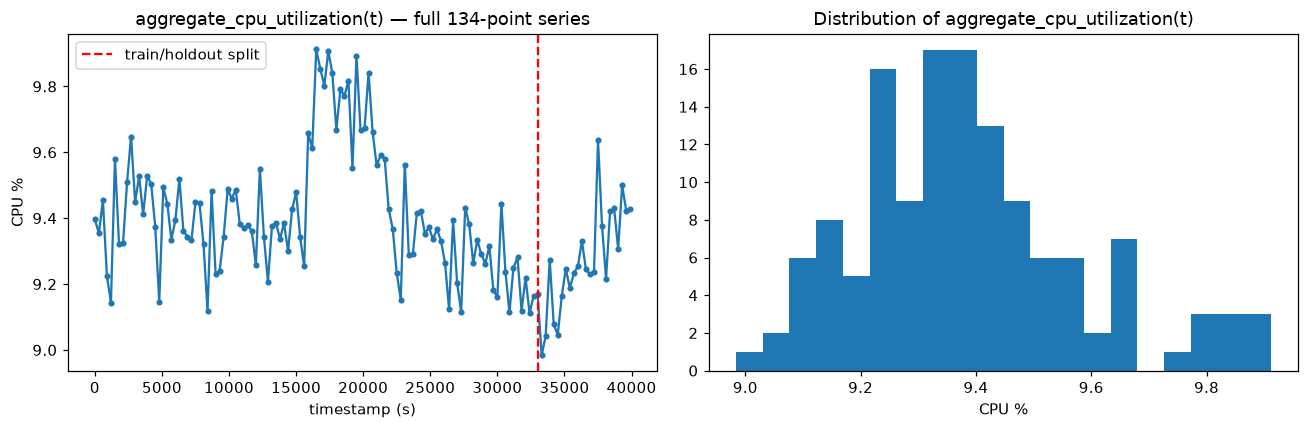

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(targets["timestamp"], targets["aggregate_cpu_utilization"], marker="o", markersize=3)
axes[0].set_title("aggregate_cpu_utilization(t) — full 134-point series")
axes[0].set_xlabel("timestamp (s)")
axes[0].set_ylabel("CPU %")
axes[0].axvline(targets["timestamp"].iloc[110], color="red", linestyle="--", label="train/holdout split")
axes[0].legend()

axes[1].hist(targets["aggregate_cpu_utilization"], bins=20)
axes[1].set_title("Distribution of aggregate_cpu_utilization(t)")
axes[1].set_xlabel("CPU %")
plt.tight_layout()
plt.savefig(FIG_DIR / "target_series_and_distribution.png")
plt.show()


In [8]:

train, holdout = train_holdout_split(targets, n_holdout=24)
print("train mean/std:", train["aggregate_cpu_utilization"].mean(), train["aggregate_cpu_utilization"].std())
print("holdout mean/std:", holdout["aggregate_cpu_utilization"].mean(), holdout["aggregate_cpu_utilization"].std())
print()
print("step-to-step diff (train only) describe:")
print(train["aggregate_cpu_utilization"].diff().describe())


train mean/std: 9.414089019539007 0.19356833547362823
holdout mean/std: 9.268987733051413 0.15572447344567772

step-to-step diff (train only) describe:
count    109.000000
mean      -0.002132
std        0.158033
min       -0.274332
25%       -0.109190
50%       -0.020451
75%        0.078342
max        0.436831
Name: aggregate_cpu_utilization, dtype: float64


The series is noisy and mean-reverting: step-to-step changes (std ~0.16) are
on the same order as the overall spread (std ~0.19), and the mean shifts only
slightly (9.41% in training vs 9.27% in the holdout window) — a mild downward
drift, smaller than one standard deviation of the series itself. There is no
daily/weekly cycle to exploit: the entire observed window is only ~11 hours.

## 6. Autocorrelation — how much memory does the series have?

lag  1 (=5 min): autocorr = 0.667
lag  2 (=10 min): autocorr = 0.606
lag  3 (=15 min): autocorr = 0.681
lag  6 (=30 min): autocorr = 0.477
lag 12 (=60 min): autocorr = 0.367
lag 18 (=90 min): autocorr = -0.084
lag 24 (=120 min): autocorr = -0.026


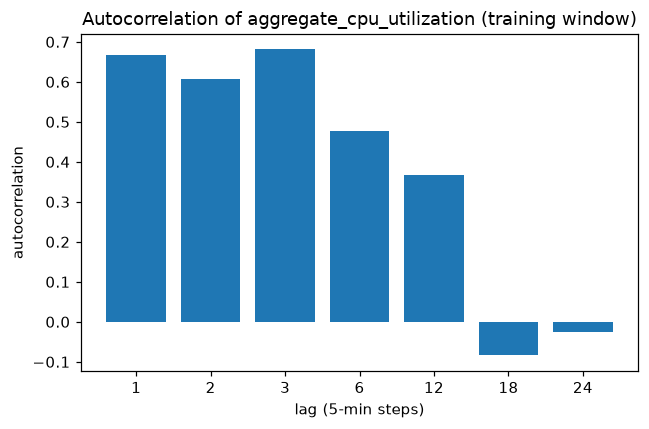

In [9]:

lags = [1, 2, 3, 6, 12, 18, 24]
acf_vals = [train["aggregate_cpu_utilization"].autocorr(l) for l in lags]
for l, v in zip(lags, acf_vals):
    print(f"lag {l:2d} (={l*5} min): autocorr = {v:.3f}")

plt.figure(figsize=(6, 4))
plt.bar([str(l) for l in lags], acf_vals)
plt.title("Autocorrelation of aggregate_cpu_utilization (training window)")
plt.xlabel("lag (5-min steps)")
plt.ylabel("autocorrelation")
plt.tight_layout()
plt.savefig(FIG_DIR / "autocorrelation.png")
plt.show()


Autocorrelation decays from 0.68 at lag 1 to roughly 0.4 by lag 12 (1 hour) and
keeps falling toward the 24-step (2-hour) horizon we must forecast. There is
real short-memory structure — this is not white noise — but the decay is fast
relative to the required horizon, so forecastability should degrade visibly as
lead time increases. We validate this directly in the error analysis by breaking
out error by step-ahead rather than reporting one pooled number.

## 7. Peaks, lows, and segment-level behavior

In [10]:

peak_idx = train["aggregate_cpu_utilization"].idxmax()
low_idx = train["aggregate_cpu_utilization"].idxmin()
print("Peak:", train.loc[peak_idx, ["timestamp", "aggregate_cpu_utilization"]].to_dict())
print("Low:", train.loc[low_idx, ["timestamp", "aggregate_cpu_utilization"]].to_dict())


Peak: {'timestamp': 16500.0, 'aggregate_cpu_utilization': 9.912175173984915}
Low: {'timestamp': 32400.0, 'aggregate_cpu_utilization': 9.111633601754887}


vm_category  Delay-insensitive  Interactive     Unknown
count               134.000000   134.000000  134.000000
mean                  8.235839    11.492567   10.233194
std                   0.205729     0.262570    0.642062
min                   7.900122    10.945942    9.035535
25%                   8.110968    11.303040    9.706388
50%                   8.176822    11.471515   10.119494
75%                   8.287265    11.687919   10.847587
max                   8.877598    12.148928   11.560735


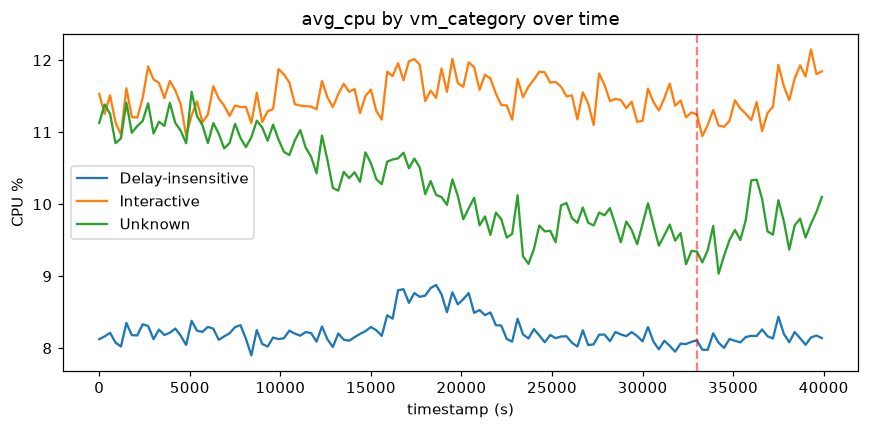

In [11]:

merged = cpu.merge(meta[["vm_id", "vm_category", "virtual_core_bucket", "memory_gb_bucket"]], on="vm_id", how="left")

seg_cat = merged.groupby(["timestamp", "vm_category"])["avg_cpu"].mean().unstack()
print(seg_cat.describe())

fig, ax = plt.subplots(figsize=(8, 4))
for col in seg_cat.columns:
    ax.plot(seg_cat.index, seg_cat[col], label=col)
ax.axvline(targets["timestamp"].iloc[110], color="red", linestyle="--", alpha=0.5)
ax.set_title("avg_cpu by vm_category over time")
ax.set_xlabel("timestamp (s)")
ax.set_ylabel("CPU %")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "segment_by_category.png")
plt.show()


VM categories sit at persistently different, well-separated CPU levels
(Delay-insensitive ≈8.2%, Unknown ≈10.2%, Interactive ≈11.5%) that are stable
across the whole window — segment composition is fixed (no churn), so this
is a level effect, not a source of the temporal drift we forecast. This explains
*why* the aggregate series has low volatility: it is a weighted average over
10,000 VMs across a few stable sub-populations, which washes out VM-level noise
by the law of large numbers. It also tells an infrastructure team that workload
category is a far bigger lever on CPU level than time-of-observation is, within
this window.

In [12]:

seg_core = merged.groupby(["timestamp", "virtual_core_bucket"])["avg_cpu"].mean().unstack()
print(seg_core.describe())


virtual_core_bucket           2          24           4           8  \
count                134.000000  134.000000  134.000000  134.000000   
mean                   9.724861   11.397470    7.928028    9.700429   
std                    0.241602    0.390291    0.221158    0.419889   
min                    9.342412   10.524673    7.405074    8.733602   
25%                    9.561419   11.106905    7.763179    9.425818   
50%                    9.680399   11.353621    7.904466    9.712034   
75%                    9.791987   11.635636    8.090670    9.940405   
max                   10.438869   12.662292    8.564606   11.133223   

virtual_core_bucket         >24  
count                134.000000  
mean                   6.617633  
std                    1.984177  
min                    3.818938  
25%                    5.240802  
50%                    6.210100  
75%                    7.256454  
max                   14.741828  


`virtual_core_bucket` does **not** show a clean, monotonic relationship with
CPU level the way `vm_category` does: mean CPU is 7.9% at 4 cores, 9.7% at
both 2 and 8 cores, 11.4% at 24 cores, but only 6.6% at the >24-core bucket --
despite that bucket being the *largest* VMs. The >24 bucket is also by far the
most volatile (std ~1.98 vs ~0.2-0.4 for the others), which is largely a small-
sample artifact: it contains only 10 of the 10,000 VMs (see the count below),
so its mean is unstable and should not be read as a real "huge VMs idle more"
effect without more data.

In [13]:
seg_mem = merged.groupby(["timestamp", "memory_gb_bucket"])["avg_cpu"].mean().unstack()
print(seg_mem.describe())
print()
print("VM counts per virtual_core_bucket:")
print(meta["virtual_core_bucket"].value_counts())
print()
print("VM counts per memory_gb_bucket:")
print(meta["memory_gb_bucket"].value_counts())

memory_gb_bucket           2          32           4          64           8  \
count             134.000000  134.000000  134.000000  134.000000  134.000000   
mean                8.775284    7.844088   11.344346   11.271343    9.182779   
std                 0.214592    0.276493    0.409085    0.456349    0.329362   
min                 8.477657    7.352291   10.514128   10.420516    8.434030   
25%                 8.624328    7.630942   11.024025   10.940745    8.921934   
50%                 8.731243    7.807797   11.339032   11.275405    9.147571   
75%                 8.833495    7.988105   11.550141   11.518868    9.422451   
max                 9.665138    8.579007   12.434091   12.689822   10.190527   

memory_gb_bucket         >64  
count             134.000000  
mean                6.617633  
std                 1.984177  
min                 3.818938  
25%                 5.240802  
50%                 6.210100  
75%                 7.256454  
max                14.741828  


`memory_gb_bucket` shows the same pattern: mean CPU is 8.8% at 2GB, 11.3% at
4GB, 9.2% at 8GB, 7.8% at 32GB, 11.3% at 64GB, and 6.6% at >64GB (again n=10,
the least reliable bucket) -- not monotonic in VM size either.

**Why this matters operationally:** unlike `vm_category`, which cleanly
separates CPU level and is stable across the whole window, provisioned size
(cores/memory) is *not* a reliable lever on CPU utilization in this sample.
This suggests workload *intent* (category) explains far more of the variation
in CPU level than how large the VM was provisioned to be -- an infrastructure
team using this data to reason about utilization should weight workload
category much more heavily than instance size when estimating expected load,
and should treat any size-bucket-level conclusion for the `>24`/`>64` buckets
as low-confidence given only 10 VMs support it.

## 8. Summary of EDA findings for the report

1. The data is clean: regular 5-minute grid, no gaps, no duplicates, no missing
   readings, and VM-level `min<=avg<=max` holds everywhere.
2. `active_vm_count(t)` is exactly 10,000 at all 134 timestamps -- a direct
   consequence of the dataset only including VMs with complete traces. There is
   no churn to forecast; the correct model is the constant 10,000, and this is
   an artifact of sampling, not a real-world property worth hiding.
3. `aggregate_cpu_utilization(t)` ranges roughly 9.0-9.9%, is noisy and
   mean-reverting (no trend, no seasonality possible in an 11-hour window), has
   real but fast-decaying autocorrelation, and drifts mildly downward from
   training into the holdout window.
4. `vm_category` explains a large, stable share of CPU level (Delay-insensitive
   ~8.2%, Unknown ~10.2%, Interactive ~11.5%) and is useful for interpreting
   the aggregate's low volatility and for optional segment-level analysis.
5. `virtual_core_bucket` and `memory_gb_bucket` do **not** show a clean,
   monotonic relationship with CPU level -- provisioned VM size is a much
   weaker and noisier lever on utilization than workload category in this
   sample, and the largest-size buckets (n=10) are too small to draw reliable
   conclusions from.
